# Is the Initial Student Better Than the Teacher?

**Objective.** GPL trains a bi-encoder (*student*) to imitate a cross-encoder (*teacher*). This only makes sense if the teacher ranks documents better than the student **before training**. This notebook tests that assumption without training any models.

## Models

- **Our students** (our unadapted candidates):
  - `BGE (our student)`: `BAAI/bge-small-en-v1.5`
  - `MiniLM (our student)`: `sentence-transformers/all-MiniLM-L6-v2`
- **Teacher:** `cross-encoder/ms-marco-MiniLM-L6-v2`, the cross-encoder used by GPL.

All students use **unnormalized dot-product similarity** for scoring, consistent with the GPL training setup. All models use a **maximum sequence length of 350 tokens**, matching GPL.

**Datasets:** SciFact, NFCorpus, and ArguAna, using **all queries from the `test` split**.

## GPL Paper Checkpoints

Due to computational limitations, we were unable to complete GPL training ourselves. Instead, we use the pretrained checkpoints released by the paper's authors, one for each dataset:

| Dataset | Final checkpoint |
|---|---|
| SciFact | `GPL/scifact-msmarco-distilbert-gpl` |
| NFCorpus | `GPL/nfcorpus-msmarco-distilbert-gpl` |
| ArguAna | `GPL/arguana-msmarco-distilbert-gpl` |

The model cards for SciFact and ArguAna confirm the following training configuration:

- **Training steps:** 140,000
- **Batch size:** 32
- **Learning rate:** 2e-5
- **Warmup steps:** 1,000
- **Loss:** MarginMSE
- **Optimizer:** AdamW

According to the GPL repository, the paper's experiments start from `GPL/msmarco-distilbert-margin-mse`, a DistilBERT model already trained on MS MARCO using MarginMSE, and use the same teacher, `cross-encoder/ms-marco-MiniLM-L6-v2`.

We therefore include two additional students from the original paper:

- **`DistilBERT (GPL paper base)`**: `GPL/msmarco-distilbert-margin-mse`, the unadapted starting checkpoint used in the paper, evaluated on all three datasets.
- **`DistilBERT-GPL (paper final checkpoint)`**: the final GPL checkpoint for each dataset, evaluated only on its corresponding dataset.

This allows us to investigate two additional questions:

1. **Did the teacher have anything to teach the paper's initial student?** We compare `DistilBERT (GPL paper base)` against the teacher.
2. **Does the paper's student outperform the teacher after GPL training?** We compare `DistilBERT-GPL (paper final checkpoint)` against the teacher.

The difference between the two paper checkpoints measures the performance improvement achieved through GPL adaptation.

## Notebook Steps

1. **Load the datasets.**
2. **Retrieve candidates for teacher evaluation:** BM25 (top-100) and two dense retrievers (top-50 each).
3. **Retrieve candidates using the students:** top-100 documents from each student.
4. **Build a shared candidate pool** for every query by merging all retrieved documents, ensuring that every model ranks the same set of candidates.
5. **Score the shared candidate pool** using the teacher.
6. **Compute nDCG@10** and statistically compare each student against the teacher.
7. **Present the results:** one figure, a student-versus-teacher comparison table, and a table reporting the GPL checkpoint results.


## **0. Installation**

In [3]:
!pip install -q beir sentence-transformers bm25s PyStemmer scipy pandas matplotlib numpy

## **1. Configuration**

In [ ]:
import os
import random

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# Datasets of BEIR to evaluate
DATASETS = ["scifact", "nfcorpus", "arguana"]

# Students (bi-encoders, off-the-shelf), evaluated on every dataset
STUDENT_MODELS = {
    "BGE (our student)": "BAAI/bge-small-en-v1.5",
    "MiniLM (our student)": "sentence-transformers/all-MiniLM-L6-v2",
    "DistilBERT (GPL paper starting point)": "GPL/msmarco-distilbert-margin-mse",   # starting point of the GPL paper
}

# GPL checkpoints released with the paper: one per dataset, evaluated only on its own dataset
GPL_PAPER_CHECKPOINTS = {
    "scifact": "GPL/scifact-msmarco-distilbert-gpl",
    "nfcorpus": "GPL/nfcorpus-msmarco-distilbert-gpl",
    "arguana": "GPL/arguana-msmarco-distilbert-gpl",
}

# Teacher (cross-encoder)
TEACHER_NAME = "MiniLM-L6 (GPL and OURS)"
TEACHER_MODEL = "cross-encoder/ms-marco-MiniLM-L6-v2"

# Dense retrievers that GPL uses for hard-negative mining
DENSE_RETRIEVERS = [
    "sentence-transformers/msmarco-distilbert-base-v3",
    "sentence-transformers/msmarco-MiniLM-L-6-v3",
]

# How many documents each retriever gives
BM25_TOP_K = 100
DENSE_TOP_K = 50
STUDENT_TOP_K = 100

# Speed settings
MAX_SEQ_LENGTH = 350            
USE_FP16 = True                 # half precision on GPU (faster)
BATCH_SIZE = 128

# Statistics
BOOTSTRAP_SAMPLES = 2000

OUTPUT_DIR = "./student_vs_teacher"
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

## 2. Load the Data

**For each dataset, we store the following in `data[dataset_name]`:**

- `doc_ids` and `doc_texts`: the documents (title + text, following GPL).
- `query_ids` and `query_texts`: all queries from the test split.
- `qrels`: the relevance judgments indicating which documents are relevant to each query.

In [ ]:
from beir import util
from beir.datasets.data_loader import GenericDataLoader

data = {}

for dataset_name in DATASETS:
    url = f"https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/{dataset_name}.zip"
    dataset_path = util.download_and_unzip(url, os.path.join(OUTPUT_DIR, "datasets"))
    corpus, queries, qrels = GenericDataLoader(dataset_path).load(split="test")

    # Documents: title + text
    doc_ids = []
    doc_texts = []
    for doc_id, doc in corpus.items():
        text = (doc.get("title", "") + " " + doc.get("text", "")).strip()
        doc_ids.append(doc_id)
        doc_texts.append(text)

    # Queries: all test queries (the ones that have relevance judgements)
    query_ids = sorted(qrels.keys())
    query_texts = [queries[query_id] for query_id in query_ids]

    data[dataset_name] = {
        "doc_ids": doc_ids,
        "doc_texts": doc_texts,
        "query_ids": query_ids,
        "query_texts": query_texts,
        "qrels": qrels,
    }
    print(f"{dataset_name}: {len(doc_ids)} documents, {len(query_ids)} queries")

  0%|          | 0/5183 [00:00<?, ?it/s]

scifact: 5183 documents, 300 queries


  0%|          | 0/3633 [00:00<?, ?it/s]

nfcorpus: 3633 documents, 323 queries


  0%|          | 0/8674 [00:00<?, ?it/s]

arguana: 8674 documents, 1406 queries


## 3. Helper Function: Select the Top-Ranked Documents

All dense models produce a **score matrix** of shape `(n_queries, n_docs)`. For each query, this function selects the `top_k` documents with the highest scores.

In ArguAna, each query is also a document in the corpus, sharing the same ID. BEIR excludes this document from retrieval, so we follow the same convention.

The output is a dictionary in BEIR format: `{query_id: {doc_id: score}}`.

In [ ]:
def get_top_k(score_matrix, query_ids, doc_ids, top_k):
    results = {}
    for row, query_id in enumerate(query_ids):
        scores_of_this_query = score_matrix[row]
        best_columns = np.argsort(-scores_of_this_query)   # from highest to lowest score

        results[query_id] = {}
        for column in best_columns:
            doc_id = doc_ids[column]
            if doc_id == query_id:          # ArguAna: skip the query itself
                continue
            results[query_id][doc_id] = float(scores_of_this_query[column])
            if len(results[query_id]) == top_k:
                break
    return results

## **4. Teacher Candidates (1/2): BM25**

In [ ]:
import bm25s
import Stemmer

stemmer = Stemmer.Stemmer("english")
bm25_results = {}

for dataset_name in DATASETS:
    d = data[dataset_name]

    # Build the BM25 index with all the documents
    doc_tokens = bm25s.tokenize(d["doc_texts"], stopwords="en", stemmer=stemmer)
    bm25 = bm25s.BM25()
    bm25.index(doc_tokens)

    # Score every document for every query (small corpora, so this is fine)
    query_tokens = bm25s.tokenize(d["query_texts"], stopwords="en", stemmer=stemmer)
    doc_indices, scores = bm25.retrieve(query_tokens, k=len(d["doc_ids"]))

    # Put the scores in a (n_queries, n_docs) matrix to reuse get_top_k
    score_matrix = np.zeros((len(d["query_ids"]), len(d["doc_ids"])))
    for row in range(len(d["query_ids"])):
        score_matrix[row, doc_indices[row]] = scores[row]

    bm25_results[dataset_name] = get_top_k(score_matrix, d["query_ids"], d["doc_ids"], BM25_TOP_K)
    print(f"{dataset_name}: BM25 done")

Split strings:   0%|          | 0/5183 [00:00<?, ?it/s]

Stem Tokens:   0%|          | 0/5183 [00:00<?, ?it/s]

BM25S Count Tokens:   0%|          | 0/5183 [00:00<?, ?it/s]

BM25S Compute Scores:   0%|          | 0/5183 [00:00<?, ?it/s]

Split strings:   0%|          | 0/300 [00:00<?, ?it/s]

Stem Tokens:   0%|          | 0/300 [00:00<?, ?it/s]

... (14 outputs left out)

Split strings:   0%|          | 0/1406 [00:00<?, ?it/s]

Stem Tokens:   0%|          | 0/1406 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1406 [00:00<?, ?it/s]

arguana: BM25 done


## 5. Teacher Candidates (2/2): GPL Dense Retrievers

They use cosine similarity and their default maximum sequence length, as in GPL's hard-negative mining step. They are used only to select candidate documents.

In [ ]:
from sentence_transformers import SentenceTransformer

dense_results = {}   # dense_results[dataset_name][retriever_name]

for dataset_name in DATASETS:
    dense_results[dataset_name] = {}

for retriever_name in DENSE_RETRIEVERS:
    model = SentenceTransformer(retriever_name, device=device)   # default max length of the model
    if USE_FP16 and device == "cuda":
        model.half()

    for dataset_name in DATASETS:
        d = data[dataset_name]
        doc_embeddings = model.encode(d["doc_texts"], batch_size=BATCH_SIZE, normalize_embeddings=True, show_progress_bar=True)
        query_embeddings = model.encode(d["query_texts"], batch_size=BATCH_SIZE, normalize_embeddings=True)
        doc_embeddings = doc_embeddings.astype(np.float32)
        query_embeddings = query_embeddings.astype(np.float32)

        score_matrix = query_embeddings @ doc_embeddings.T   # cosine similarity (embeddings are normalized)
        dense_results[dataset_name][retriever_name] = get_top_k(score_matrix, d["query_ids"], d["doc_ids"], DENSE_TOP_K)
        print(f"{dataset_name}: {retriever_name} done")

    del model
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

scifact: sentence-transformers/msmarco-distilbert-base-v3 done


Batches:   0%|          | 0/29 [00:00<?, ?it/s]

nfcorpus: sentence-transformers/msmarco-distilbert-base-v3 done


Batches:   0%|          | 0/68 [00:00<?, ?it/s]

... (4 outputs left out)

Batches:   0%|          | 0/29 [00:00<?, ?it/s]

nfcorpus: sentence-transformers/msmarco-MiniLM-L-6-v3 done


Batches:   0%|          | 0/68 [00:00<?, ?it/s]

arguana: sentence-transformers/msmarco-MiniLM-L-6-v3 done


## 6. Students: Retrieve from the Full Corpus

GPL uses **unnormalized dot-product similarity** for scoring. BGE and MiniLM end with a `Normalize` layer, which makes the dot product equivalent to cosine similarity. Therefore, we:

1. Load the complete model.
2. Create a copy containing only the first two layers (`Transformer` + `Pooling`), removing `Normalize`.
3. Compute embeddings using this copy and calculate their dot products.

The DistilBERT models from the paper do not have a `Normalize` layer (they already use dot-product scoring), so step 2 leaves them unchanged.

The `students_to_run` list combines the students defined in `STUDENT_MODELS`, which are evaluated on all datasets, with the paper's final checkpoints, each evaluated only on its corresponding dataset.

For each student, we store the full score matrix (`student_scores`) and its top-100 retrieval results (`student_results`).

In [ ]:
student_scores = {}    # student_scores[dataset_name][student_name] = (n_queries, n_docs) matrix
student_results = {}   # student_results[dataset_name][student_name] = {query_id: {doc_id: score}}

for dataset_name in DATASETS:
    student_scores[dataset_name] = {}
    student_results[dataset_name] = {}

# (student name, model id, datasets where it is evaluated)
students_to_run = []
for student_name, student_model in STUDENT_MODELS.items():
    students_to_run.append((student_name, student_model, DATASETS))
for dataset_name, checkpoint in GPL_PAPER_CHECKPOINTS.items():
    if dataset_name in DATASETS:
        students_to_run.append(("DistilBERT-GPL (paper final checkpoint)", checkpoint, [dataset_name]))

for student_name, student_model, student_datasets in students_to_run:
    full_model = SentenceTransformer(student_model, device=device)
    print(student_name, student_model, "modules:", [type(module).__name__ for module in full_model])

    # Keep only Transformer + Pooling, drop Normalize
    model = SentenceTransformer(modules=[full_model[0], full_model[1]], device=device)
    model.max_seq_length = MAX_SEQ_LENGTH
    if USE_FP16 and device == "cuda":
        model.half()

    for dataset_name in student_datasets:
        d = data[dataset_name]
        doc_embeddings = model.encode(d["doc_texts"], batch_size=BATCH_SIZE, show_progress_bar=True)
        query_embeddings = model.encode(d["query_texts"], batch_size=BATCH_SIZE)
        doc_embeddings = doc_embeddings.astype(np.float32)
        query_embeddings = query_embeddings.astype(np.float32)

        # Dot product without normalization (how GPL trains the student)
        score_matrix = query_embeddings @ doc_embeddings.T

        student_scores[dataset_name][student_name] = score_matrix
        student_results[dataset_name][student_name] = get_top_k(score_matrix, d["query_ids"], d["doc_ids"], STUDENT_TOP_K)
        print(f"{dataset_name}: {student_name} done")

    del model, full_model
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BGE (our student) BAAI/bge-small-en-v1.5 modules: ['Transformer', 'Pooling', 'Normalize']


Batches:   0%|          | 0/41 [00:00<?, ?it/s]

scifact: BGE (our student) done


Batches:   0%|          | 0/29 [00:00<?, ?it/s]

nfcorpus: BGE (our student) done


... (26 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBERT-GPL (paper final checkpoint) GPL/arguana-msmarco-distilbert-gpl modules: ['Transformer', 'Pooling']


Batches:   0%|          | 0/68 [00:00<?, ?it/s]

arguana: DistilBERT-GPL (paper final checkpoint) done


## 7. Shared Candidate Pool

For each query, the shared candidate pool is the union of:

- **Teacher candidates:** BM25 and the two dense retrievers.
- **Student candidates:** the top-100 documents retrieved by each student.

All models are evaluated by ranking **exactly the same set of documents**.

In [ ]:
teacher_candidates = {}   # teacher_candidates[dataset_name][query_id] = set of doc_ids
shared_pool = {}          # shared_pool[dataset_name][query_id] = set of doc_ids

for dataset_name in DATASETS:
    teacher_candidates[dataset_name] = {}
    shared_pool[dataset_name] = {}

    for query_id in data[dataset_name]["query_ids"]:
        candidates = set(bm25_results[dataset_name][query_id].keys())
        for retriever_name in DENSE_RETRIEVERS:
            candidates = candidates | set(dense_results[dataset_name][retriever_name][query_id].keys())
        teacher_candidates[dataset_name][query_id] = candidates

        pool = set(candidates)
        for student_name in student_results[dataset_name]:
            pool = pool | set(student_results[dataset_name][student_name][query_id].keys())
        shared_pool[dataset_name][query_id] = pool

    average_candidates = np.mean([len(c) for c in teacher_candidates[dataset_name].values()])
    average_pool = np.mean([len(p) for p in shared_pool[dataset_name].values()])
    print(f"{dataset_name}: teacher candidates = {average_candidates:.0f} docs/query, shared pool = {average_pool:.0f} docs/query")

scifact: teacher candidates = 166 docs/query, shared pool = 347 docs/query
nfcorpus: teacher candidates = 168 docs/query, shared pool = 374 docs/query
arguana: teacher candidates = 138 docs/query, shared pool = 295 docs/query


## **8. Teacher Scoring on the Shared Candidate Pool**

The cross-encoder scores each (query, document) pair in the shared candidate pool.

In [ ]:
from sentence_transformers import CrossEncoder

teacher = CrossEncoder(TEACHER_MODEL, max_length=MAX_SEQ_LENGTH, device=device)
if USE_FP16 and device == "cuda":
    teacher.model.half()

teacher_pool_scores = {}   # teacher_pool_scores[dataset_name][query_id][doc_id] = score

for dataset_name in DATASETS:
    d = data[dataset_name]
    doc_text_by_id = dict(zip(d["doc_ids"], d["doc_texts"]))
    query_text_by_id = dict(zip(d["query_ids"], d["query_texts"]))

    # 1) list all (query, document) pairs of the pool
    pair_ids = []
    pair_texts = []
    for query_id in d["query_ids"]:
        for doc_id in shared_pool[dataset_name][query_id]:
            pair_ids.append((query_id, doc_id))
            pair_texts.append((query_text_by_id[query_id], doc_text_by_id[doc_id]))

    # 2) score all pairs with the cross-encoder
    scores = teacher.predict(pair_texts, batch_size=BATCH_SIZE, show_progress_bar=True)

    # 3) store the scores by query and document
    teacher_pool_scores[dataset_name] = {query_id: {} for query_id in d["query_ids"]}
    for (query_id, doc_id), score in zip(pair_ids, scores):
        teacher_pool_scores[dataset_name][query_id][doc_id] = float(score)
    print(f"{dataset_name}: {len(pair_texts)} pairs scored")

del teacher
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Batches:   0%|          | 0/813 [00:00<?, ?it/s]

scifact: 104019 pairs scored


Batches:   0%|          | 0/943 [00:00<?, ?it/s]

nfcorpus: 120645 pairs scored


Batches:   0%|          | 0/3240 [00:00<?, ?it/s]

arguana: 414681 pairs scored


## 9. Evaluation Metrics

**nDCG@10** (computed using `pytrec_eval`, the same library used by BEIR): measures the ranking quality of the top 10 results, on a scale from 0 to 1.

The metric is computed **per query**, allowing us to perform query-level comparisons between models.

In [ ]:
import pytrec_eval


def ndcg_at_10_per_query(qrels, results, query_ids):
    evaluator = pytrec_eval.RelevanceEvaluator(qrels, {"ndcg_cut.10"})
    scores = evaluator.evaluate(results)
    values = []
    for query_id in query_ids:
        if query_id in scores:
            values.append(scores[query_id]["ndcg_cut_10"])
        else:
            values.append(0.0)
    return np.array(values)

In [ ]:
# metrics[dataset_name][system_name] = {"ndcg": per-query nDCG@10 array}
metrics = {}

for dataset_name in DATASETS:
    d = data[dataset_name]
    qrels = d["qrels"]
    query_ids = d["query_ids"]
    metrics[dataset_name] = {}

    # Students: their top-10 is inside the shared pool (the pool contains their top-100),
    # so ranking the pool or the whole corpus gives the same nDCG@10
    for student_name in student_results[dataset_name]:
        metrics[dataset_name][student_name] = {
            "ndcg": ndcg_at_10_per_query(qrels, student_results[dataset_name][student_name], query_ids),
        }

    # Teacher on the shared pool
    metrics[dataset_name][TEACHER_NAME] = {
        "ndcg": ndcg_at_10_per_query(qrels, teacher_pool_scores[dataset_name], query_ids),
    }

print("Metrics done")

Metrics done


## 10. Compare each student with the teacher

For each query, we calculate the difference `student − teacher`:
- **Positive** → the student performs better on that query.
- **Negative** → the teacher performs better.

From these differences, we calculate:
- **Mean difference** (`delta`).
- **95% bootstrap confidence interval**: repeat `BOOTSTRAP_SAMPLES` times, sampling queries with replacement and computing the mean.
- **Wilcoxon signed-rank test p-value**: a standard nonparametric test for paired observations.

**Interpretation:**
- **Entire confidence interval below 0** → the teacher performs better, suggesting that GPL may be beneficial.
- **Entire confidence interval above 0** → the student already performs better, suggesting that GPL may not provide an improvement.
- **Confidence interval includes 0** → no clear difference in mean performance.

In [ ]:
from scipy.stats import wilcoxon


def compare_student_with_teacher(student_values, teacher_values):
    # remove queries where one of the two values is missing (NaN)
    differences = []
    for s, t in zip(student_values, teacher_values):
        if not np.isnan(s) and not np.isnan(t):
            differences.append(s - t)
    differences = np.array(differences)

    # bootstrap confidence interval of the mean difference
    rng = np.random.default_rng(SEED)
    bootstrap_means = []
    for _ in range(BOOTSTRAP_SAMPLES):
        sample = rng.choice(differences, size=len(differences), replace=True)
        bootstrap_means.append(sample.mean())
    ci_low = np.percentile(bootstrap_means, 2.5)
    ci_high = np.percentile(bootstrap_means, 97.5)

    # Wilcoxon signed-rank test
    if np.all(differences == 0):
        p_value = 1.0
    else:
        p_value = wilcoxon(differences, zero_method="zsplit").pvalue

    if ci_high < 0:
        verdict = "Teacher better -> GPL makes sense"
    elif ci_low > 0:
        verdict = "Student already better -> GPL will likely hurt it"
    else:
        verdict = "No clear difference"

    return {
        "delta": differences.mean(),
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_wilcoxon": p_value,
        "student_wins": int((differences > 0).sum()),
        "ties": int((differences == 0).sum()),
        "teacher_wins": int((differences < 0).sum()),
        "verdict": verdict,
    }

In [ ]:
comparison_rows = []

for dataset_name in DATASETS:
    teacher = metrics[dataset_name][TEACHER_NAME]

    for student_name in student_results[dataset_name]:
        student = metrics[dataset_name][student_name]
        stats = compare_student_with_teacher(student["ndcg"], teacher["ndcg"])

        comparison_rows.append({
            "dataset": dataset_name,
            "student": student_name,
            "nDCG@10 student": 100 * student["ndcg"].mean(),
            "nDCG@10 teacher": 100 * teacher["ndcg"].mean(),
            "Δ (student − teacher)": 100 * stats["delta"],
            "CI 95% low": 100 * stats["ci_low"],
            "CI 95% high": 100 * stats["ci_high"],
            "p (Wilcoxon)": stats["p_wilcoxon"],
            "student wins": stats["student_wins"],
            "ties": stats["ties"],
            "teacher wins": stats["teacher_wins"],
            "verdict": stats["verdict"],
        })

comparisons = pd.DataFrame(comparison_rows)
comparisons.to_csv(os.path.join(OUTPUT_DIR, "comparisons.csv"), index=False)

## 11. Results


### **Plot: Student vs. Teacher**

Each point represents the mean nDCG\@10 difference (`student − teacher`) over the common candidate pool, with its 95% confidence interval. Values to the right of zero favor the student, while values to the left favor the teacher. If the confidence interval crosses zero, there is no clear difference in mean performance.

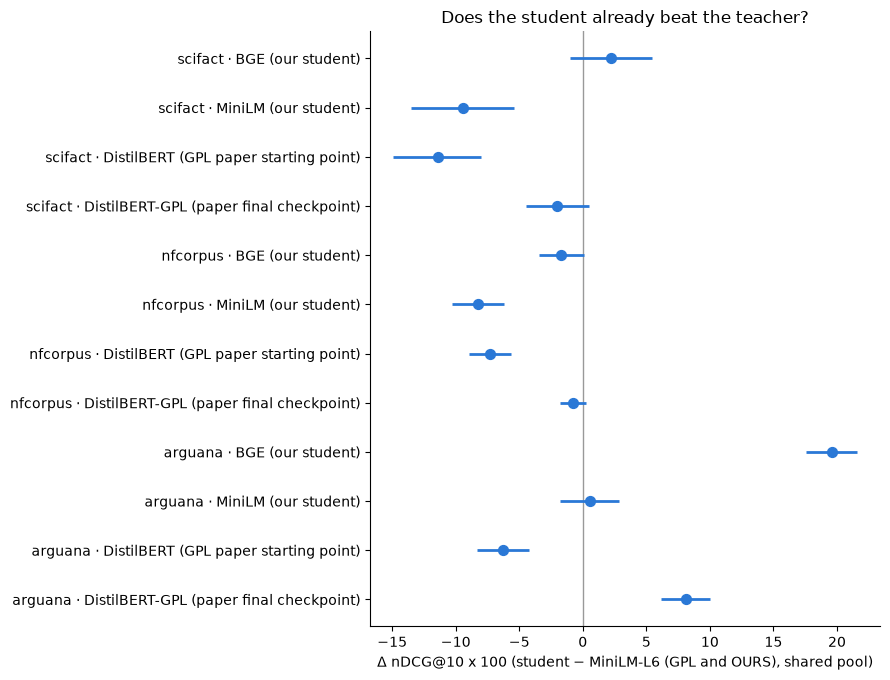

In [ ]:
import matplotlib.pyplot as plt

labels = comparisons["dataset"] + " · " + comparisons["student"]
y_positions = np.arange(len(comparisons))[::-1]

fig, ax = plt.subplots(figsize=(9, 0.45 * len(comparisons) + 1.5))
ax.axvline(0, color="#999999", linewidth=1)
ax.hlines(y_positions, comparisons["CI 95% low"], comparisons["CI 95% high"], color="#2a78d6", linewidth=2)
ax.scatter(comparisons["Δ (student − teacher)"], y_positions, color="#2a78d6", s=50, zorder=3)
ax.set_yticks(y_positions)
ax.set_yticklabels(labels)
ax.set_xlabel(f"Δ nDCG@10 x 100 (student − {TEACHER_NAME}, shared pool)")
ax.set_title("Does the student already beat the teacher?")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "student_vs_teacher.png"), dpi=150)
plt.show()

### **Table: Student vs. Teacher**

nDCG\@10 (×100) evaluated on the common candidate pool. `Δ` represents the mean difference (`student − teacher`); positive values favor the student. The verdict is based on the 95% confidence interval.

In [ ]:
comparisons.round(2)

,dataset,student,nDCG@10 student,nDCG@10 teacher,Δ (student − teacher),CI 95% low,CI 95% high,p (Wilcoxon),student wins,ties,teacher wins,verdict
0,scifact,BGE (our student),70.69,68.47,2.22,-1.04,5.48,0.23,64,186,50,No clear difference
1,scifact,MiniLM (our student),59.02,68.47,-9.45,-13.49,-5.43,0.00,49,154,97,Teacher better -> GPL makes sense
2,scifact,DistilBERT (GPL paper starting point),57.08,68.47,-11.39,-14.92,-7.97,0.00,28,181,91,Teacher better -> GPL makes sense
3,scifact,DistilBERT-GPL (paper final checkpoint),66.41,68.47,-2.06,-4.46,0.46,0.94,52,201,47,No clear difference
4,nfcorpus,BGE (our student),33.26,34.95,-1.69,-3.46,0.06,0.03,88,116,119,No clear difference
5,nfcorpus,MiniLM (our student),26.73,34.95,-8.22,-10.27,-6.20,0.00,61,101,161,Teacher better -> GPL makes sense
6,nfcorpus,DistilBERT (GPL paper starting point),27.66,34.95,-7.28,-8.94,-5.65,0.00,46,125,152,Teacher better -> GPL makes sense
7,nfcorpus,DistilBERT-GPL (paper final checkpoint),34.16,34.95,-0.78,-1.76,0.22,0.49,80,157,86,No clear difference
8,arguana,BGE (our student),59.74,40.16,19.59,17.53,21.56,0.00,751,413,242,Student already better -> GPL will likely hurt it
9,arguana,MiniLM (our student),40.70,40.16,0.54,-1.78,2.83,0.97,529,338,539,No clear difference


### **Table: GPL Checkpoints from the Paper**

nDCG\@10 (×100) by dataset, comparing the paper's student model before and after GPL training, alongside the teacher.

- `GPL gain` = after − before: the improvement achieved through GPL training.
- `final − teacher`: whether the paper's GPL-trained student outperforms the teacher.

In [ ]:
gpl_rows = []
for dataset_name in DATASETS:
    if "DistilBERT-GPL (paper final checkpoint)" not in metrics[dataset_name]:
        continue
    base_ndcg = 100 * metrics[dataset_name]["DistilBERT (GPL paper starting point)"]["ndcg"].mean()
    final_ndcg = 100 * metrics[dataset_name]["DistilBERT-GPL (paper final checkpoint)"]["ndcg"].mean()
    teacher_ndcg = 100 * metrics[dataset_name][TEACHER_NAME]["ndcg"].mean()
    gpl_rows.append({
        "dataset": dataset_name,
        "before GPL (GPL paper starting point)": base_ndcg,
        "after GPL (final checkpoint)": final_ndcg,
        "teacher": teacher_ndcg,
        "GPL gain": final_ndcg - base_ndcg,
        "final − teacher": final_ndcg - teacher_ndcg,
    })

gpl_checkpoints = pd.DataFrame(gpl_rows)
gpl_checkpoints.to_csv(os.path.join(OUTPUT_DIR, "gpl_checkpoints.csv"), index=False)
gpl_checkpoints.round(2)

,dataset,before GPL (GPL paper starting point),after GPL (final checkpoint),teacher,GPL gain,final − teacher
0,scifact,57.08,66.41,68.47,9.33,-2.06
1,nfcorpus,27.66,34.16,34.95,6.50,-0.78
2,arguana,33.86,48.24,40.16,14.38,8.08
